# ML Direct models

## Setup

In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

from src.config import GB_PARAMS, HORIZONS, N_TEST, RF_PARAMS
from src.evaluation import error_metrics
from src.ML_models import direct_lags, make_supervised, tune_gb_trees
from src.visualization import plot_importances

DATA_DIR = Path("data")
FIG_DIR = Path("figures/ml_direct")
FIG_DIR.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(DATA_DIR / "model_data.csv", index_col="date", parse_dates=True)
y, X = data["x"], data.drop(columns="x")


## Best models and Error measures

In [2]:
models, forecasts, rows = {}, {}, []
for h in HORIZONS:
    X_tr, y_tr, X_te, y_te = make_supervised(X, y, direct_lags(h), N_TEST)
    n_trees, _ = tune_gb_trees(X_tr, y_tr, max_trees=1500, **GB_PARAMS)
    models[h] = {
        "RF": RandomForestRegressor(**RF_PARAMS).fit(X_tr, y_tr),
        "GBM": GradientBoostingRegressor(n_estimators=n_trees, **GB_PARAMS).fit(X_tr, y_tr),
    }
    for name, model in models[h].items():
        forecasts[f"{name}_h{h}"] = pd.Series(model.predict(X_te), index=X_te.index)
        rows.append({"h": h, "model": name, **error_metrics(y_te, forecasts[f"{name}_h{h}"])})
    print(f"h = {h:2d} | lags: {direct_lags(h)} | GBM trees: {n_trees}")

results = pd.DataFrame(rows)
display(results.pivot(index="h", columns="model", values=["RMSE", "MAE"]).round(3))


h =  1 | lags: [1, 2, 7, 14] | GBM trees: 686


h =  3 | lags: [3, 4, 7, 14] | GBM trees: 653


h =  7 | lags: [7, 8, 14, 21] | GBM trees: 707


h = 14 | lags: [14, 15, 21, 28] | GBM trees: 607


h = 30 | lags: [30, 31, 35, 42] | GBM trees: 795


RMSE             MAE        
model     GBM      RF     GBM      RF
h                                    
1      22.682  23.434  18.163  18.654
3      23.596  24.288  18.788  19.162
7      22.888  23.893  18.418  19.134
14     24.639  26.099  19.918  20.772
30     25.278  25.860  20.641  20.785

## VI (h=1, h=30)

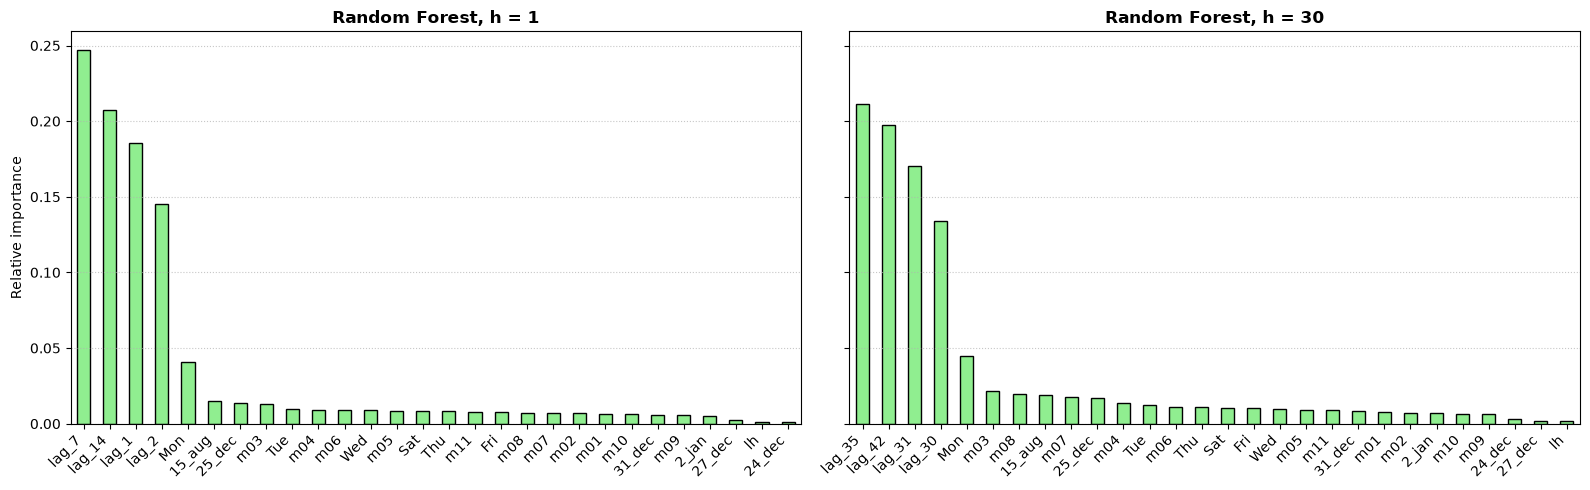

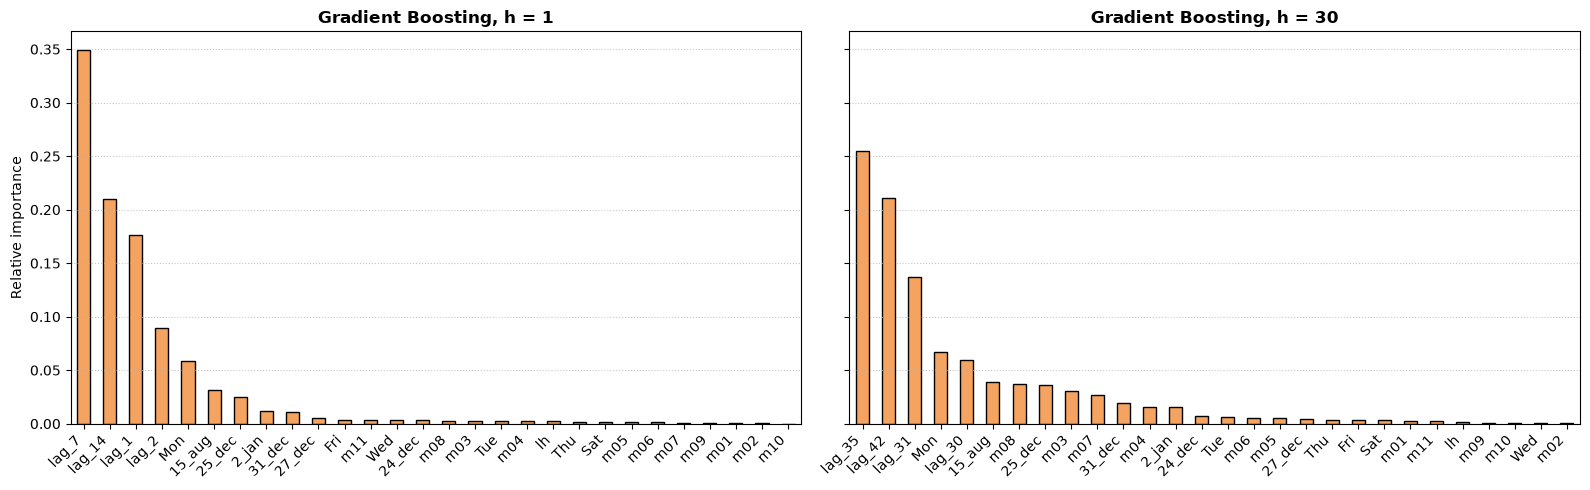

In [3]:
for name, title, color in [("RF", "Random Forest", "lightgreen"), ("GBM", "Gradient Boosting", "sandybrown")]:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
    for ax, h in zip(axes, [1, 30]):
        plot_importances(models[h][name], f"{title}, h = {h}", color=color, ax=ax)
    axes[1].set_ylabel("")  # shared axis: label only on the left panel
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name.lower()}_importance_h1_vs_h30.png", dpi=300, bbox_inches="tight")
    plt.show()

In [4]:
pd.DataFrame(forecasts).to_csv(DATA_DIR / "ml_direct_forecasts.csv", index_label="date")

## Robustness check: Direct ML on first differences

In [5]:
diff_forecasts, diff_rows = {}, []
dy = y.diff()

for h in HORIZONS:
    dy_h = y - y.shift(h)
    X_tr, _, X_te, _ = make_supervised(X, dy, direct_lags(h), N_TEST)
    _, y_tr_h, _, _ = make_supervised(X, dy_h, direct_lags(h), N_TEST)
    X_tr, y_tr_h = X_tr.iloc[1:], y_tr_h.iloc[1:]
    y_orig_te = y.shift(h).iloc[-N_TEST:]
    y_true_te = y.iloc[-N_TEST:]

    n_trees, _ = tune_gb_trees(X_tr, y_tr_h, max_trees=1500, **GB_PARAMS)
    models_diff = {
        "RF_diff": RandomForestRegressor(**RF_PARAMS).fit(X_tr, y_tr_h),
        "GBM_diff": GradientBoostingRegressor(n_estimators=n_trees, **GB_PARAMS).fit(X_tr, y_tr_h),
    }
    for name, model in models_diff.items():
        pred_diff = model.predict(X_te)
        pred_level = y_orig_te + pred_diff
        diff_forecasts[f"{name}_h{h}"] = pd.Series(pred_level, index=X_te.index)
        diff_rows.append({"h": h, "model": name, **error_metrics(y_true_te, pred_level)})
    print(f"h = {h:2d} | lags: {direct_lags(h)} | GBM diff trees: {n_trees}")

diff_results = pd.DataFrame(diff_rows)
display(diff_results.pivot(index="h", columns="model", values=["RMSE", "MAE"]).round(3))


h =  1 | lags: [1, 2, 7, 14] | GBM diff trees: 648


h =  3 | lags: [3, 4, 7, 14] | GBM diff trees: 680


h =  7 | lags: [7, 8, 14, 21] | GBM diff trees: 831


h = 14 | lags: [14, 15, 21, 28] | GBM diff trees: 973


h = 30 | lags: [30, 31, 35, 42] | GBM diff trees: 822


RMSE              MAE        
model GBM_diff RF_diff GBM_diff RF_diff
h                                      
1       23.802  24.561   18.980  19.612
3       23.942  24.323   19.339  19.636
7       23.911  24.341   19.058  19.187
14      25.420  26.367   20.363  21.069
30      26.117  26.318   21.078  21.175

## Comparison: Levels vs Differences

In [6]:
comp_df = pd.concat([results, diff_results])
display(comp_df.pivot(index="h", columns="model", values=["RMSE", "MAE"]).round(3))

pd.DataFrame(diff_forecasts).to_csv(DATA_DIR / "ml_direct_diff_forecasts.csv", index_label="date")


RMSE                              MAE                         
model     GBM GBM_diff      RF RF_diff     GBM GBM_diff      RF RF_diff
h                                                                      
1      22.682   23.802  23.434  24.561  18.163   18.980  18.654  19.612
3      23.596   23.942  24.288  24.323  18.788   19.339  19.162  19.636
7      22.888   23.911  23.893  24.341  18.418   19.058  19.134  19.187
14     24.639   25.420  26.099  26.367  19.918   20.363  20.772  21.069
30     25.278   26.117  25.860  26.318  20.641   21.078  20.785  21.175

## Baseline: Random Forest without Lags
This section evaluates a Random Forest using only exogenous calendar variables, without any autoregressive lags.

Random Forest BASE RMSE: 33.401
Random Forest BASE MAE:  28.233


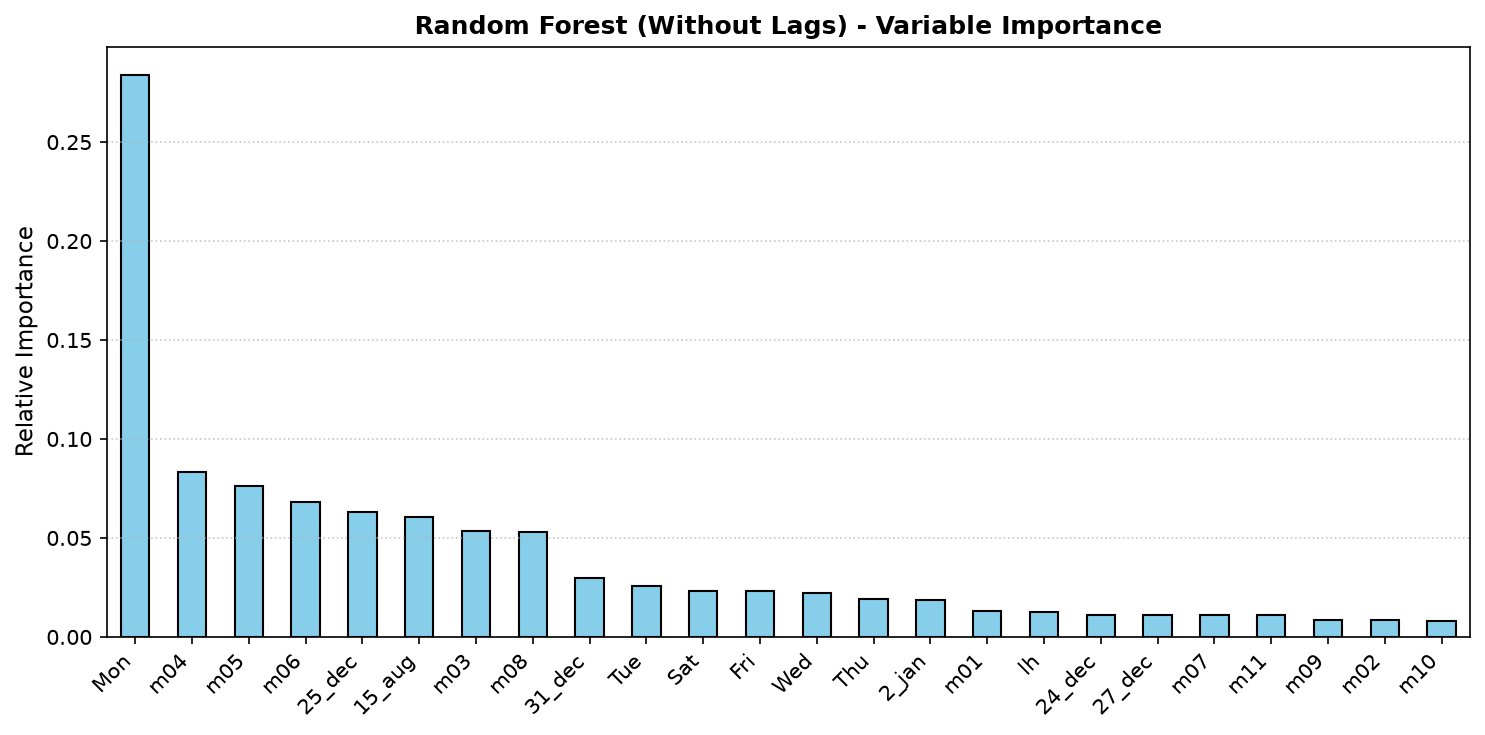

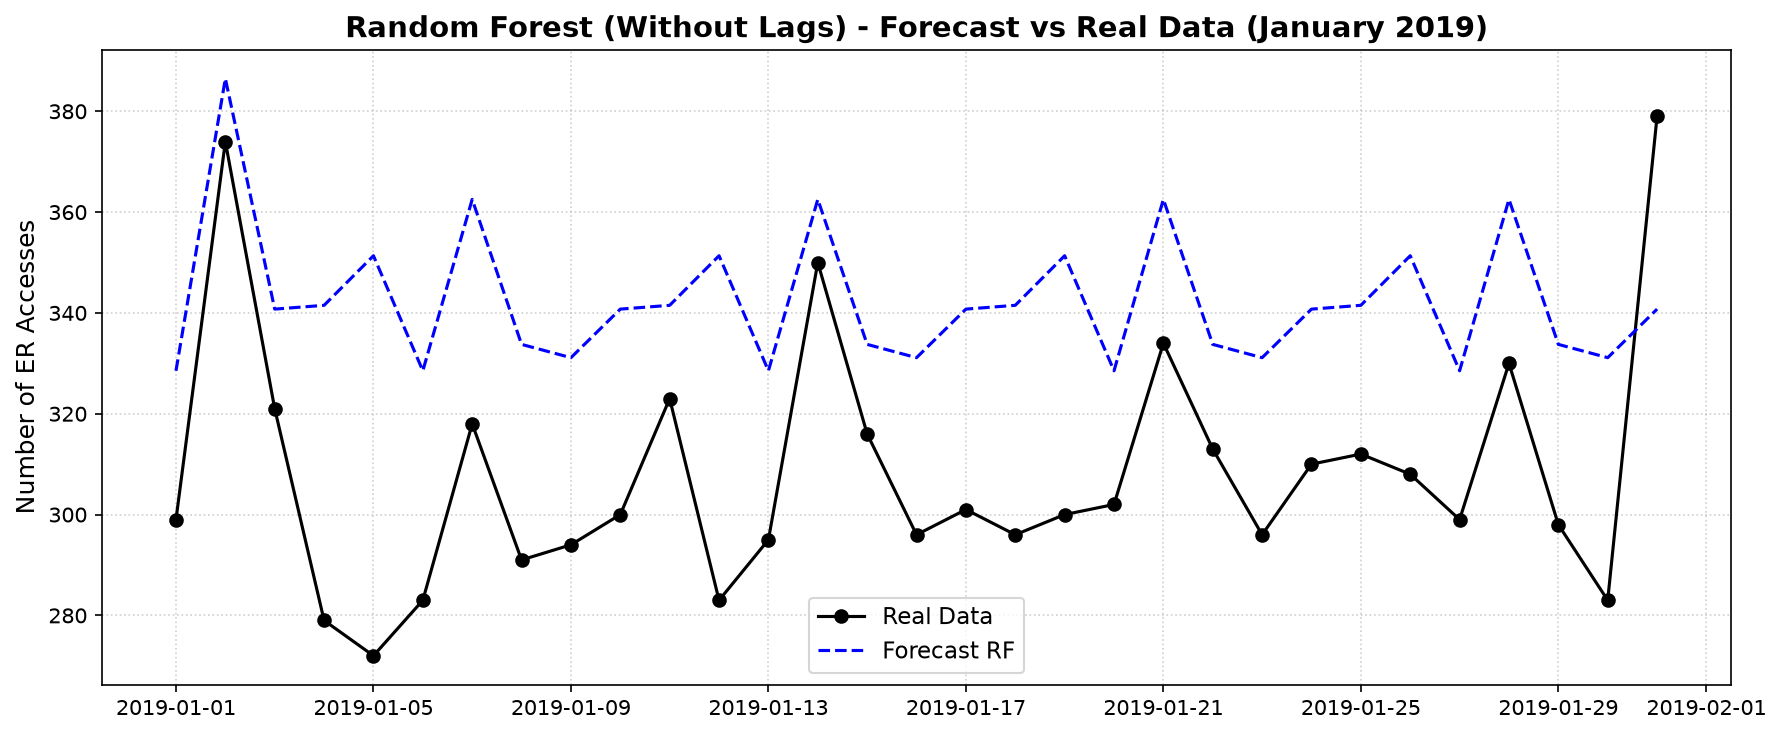

In [7]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Define train/test split directly for base data (no lags)
X_train, X_test = X.iloc[:-N_TEST], X.iloc[-N_TEST:]
y_train, y_test = y.iloc[:-N_TEST], y.iloc[-N_TEST:]

rf_base = RandomForestRegressor(n_estimators=1000, max_features=1/3, random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)

X_test = X_test[X_train.columns]
preds_base = rf_base.predict(X_test)

rmse_base = np.sqrt(mean_squared_error(y_test, preds_base))
mae_base = mean_absolute_error(y_test, preds_base)

print(f"Random Forest BASE RMSE: {rmse_base:.3f}")
print(f"Random Forest BASE MAE:  {mae_base:.3f}")

# --- 2. VARIABLE IMPORTANCE PLOT ---
plt.figure(figsize=(10, 5), dpi=150)
importances_base = pd.Series(rf_base.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances_base.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Random Forest (Without Lags) - Variable Importance", fontsize=12, fontweight='bold')
plt.ylabel("Relative Importance", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.savefig(FIG_DIR / 'RF_woLags_VI.png', dpi=300, bbox_inches='tight')
plt.show()

df_plot_base = pd.DataFrame({
    'Real Data': y_test,
    'Forecast RF': preds_base
}, index=y_test.index)

df_window_base = df_plot_base.loc['2019-01-01':'2019-01-31']

plt.figure(figsize=(12, 5), dpi=150)
plt.plot(df_window_base.index, df_window_base['Real Data'], marker='o', color='black', label='Real Data')
plt.plot(df_window_base.index, df_window_base['Forecast RF'], linestyle='--', color='blue', label='Forecast RF')
plt.title("Random Forest (Without Lags) - Forecast vs Real Data (January 2019)", fontsize=14, fontweight='bold')
plt.ylabel("Number of ER Accesses", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(FIG_DIR / 'RF_woLags_pred.png', dpi=300, bbox_inches='tight')
plt.show()